# Interpretable model V1: forest vs plantation

Predict `label_forest` (1 = natural forest, 0 = plantation) from `master_features_v3_slim.csv`, with four simple models: CART, Optimal Classification Tree (OCT), and logistic regression with lasso and with ridge.

- **Split** (from the CSV): train on `dev`, choose settings on `lockbox` (validation), score once on `heldback` (test).
- **AUC** = chance that a random forest point gets a higher forest score than a random plantation (0.5 = coin flip, 1 = perfect).
- **Plantations caught** = share of plantations called plantation at a cutoff that hides only 5% of forest (that is, calls 5% of real forest "plantation"). The cutoff is set on `lockbox` and applied unchanged to `heldback`.

In [ ]:
import pandas as pd, numpy as np, statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

28 features | {'train': 2023, 'val': 436, 'test': 207}


In [ ]:
df = pd.read_csv('../master_features_v3_slim.csv').dropna(subset=['nc_F_VH_median'])  # 1 dev row has no radar data
# |Spearman| >= 0.8 on dev: drop the weaker feature of each pair
drop = ['mm_B6_win', 'nc_B_SWIR_phase_sin', 'lh_ever_open', 'lh_n_changes', 'nc_A_SAG', 'nc_su3_NDMI']
X_cols = [c for c in df.columns[7:] if c not in drop]
y = 'label_forest'
train, val, test = (df[df.split == s] for s in ['dev', 'lockbox', 'heldback'])
print(len(X_cols), 'features |', {s: len(d) for s, d in zip(['train', 'val', 'test'], [train, val, test])})

In [2]:
def evaluate(name, p_val, p_test):
    """p_* = predicted probability of forest. Cutoff hides 5% of lockbox forest."""
    cut = np.quantile(p_val[val[y] == 1], 0.05)
    row = {'model': name}
    for s, d, p in [('val', val, p_val), ('test', test, p_test)]:
        row[f'AUC {s}'] = roc_auc_score(d[y], p)
        row[f'plantations caught {s}'] = (p[d[y] == 0] < cut).mean()
        row[f'forest hidden {s}'] = (p[d[y] == 1] < cut).mean()
    return row

def tune(make, grid):
    """Fit one model per setting on train, keep the best lockbox AUC."""
    fits = [make(g).fit(train[X_cols], train[y]) for g in grid]
    aucs = [roc_auc_score(val[y], m.predict_proba(val[X_cols])[:, 1]) for m in fits]
    return fits[int(np.argmax(aucs))], grid[int(np.argmax(aucs))]

results = []

## 1. CART (classic decision tree; depth 1–5 chosen on lockbox, capped at 5 so it stays readable)

In [3]:
cart, depth = tune(lambda d: DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, random_state=0), list(range(1, 6)))
results.append(evaluate(f'CART (depth {depth})', cart.predict_proba(val[X_cols])[:, 1], cart.predict_proba(test[X_cols])[:, 1]))


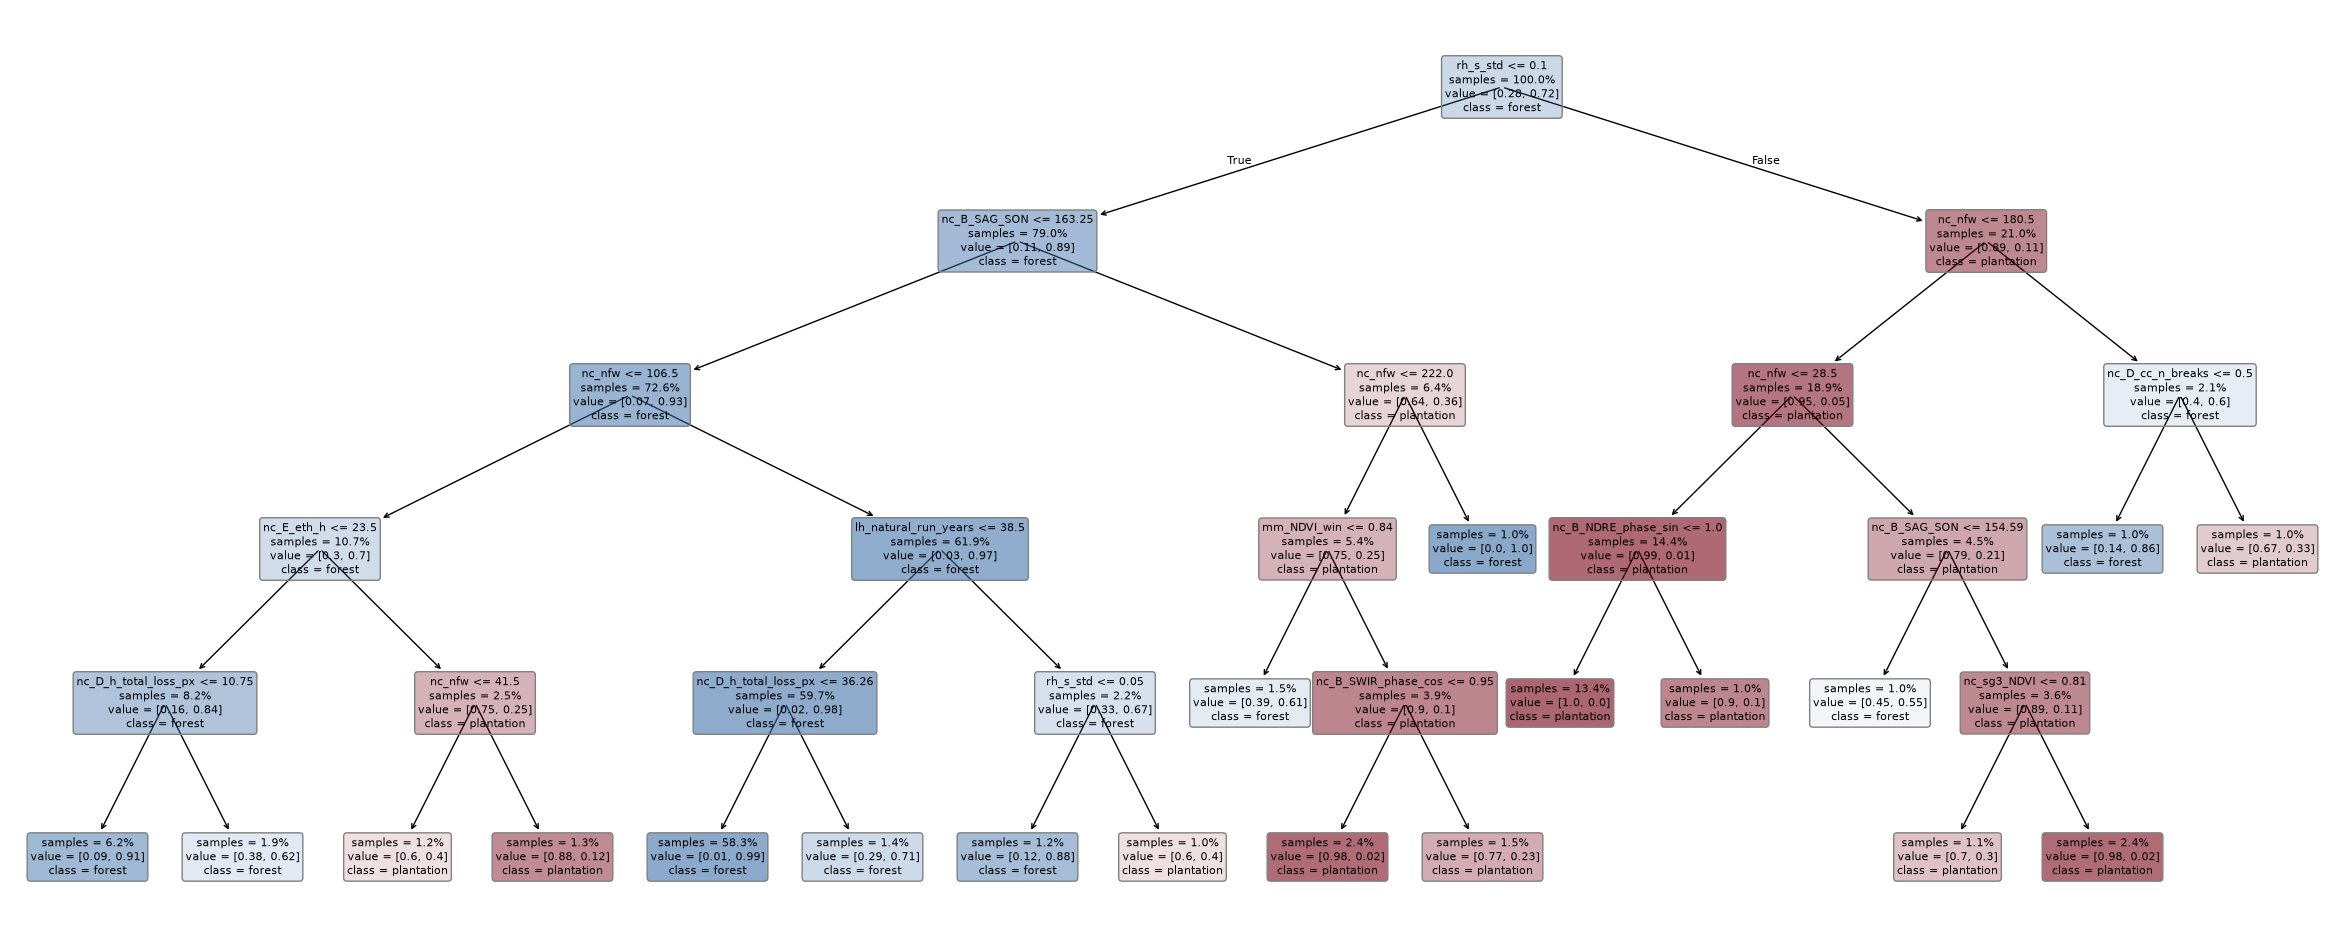

In [4]:
# Blue = forest, burgundy = plantation; darker = purer node. Each box: split rule, share of training points, class mix.
fig, ax = plt.subplots(figsize=(30, 12))
nodes = plot_tree(cart, feature_names=X_cols, class_names=['plantation', 'forest'], impurity=False, proportion=True, rounded=True, precision=2, fontsize=8, ax=ax)
for box in nodes:  # colour each node from its printed class mix [plantation, forest]
    if 'value' in box.get_text():
        f = float(box.get_text().split('value = [')[1].split(']')[0].split(',')[1])
        box.set_bbox(dict(boxstyle='round', ec='grey', fc=to_rgba('#3B6EA8' if f >= 0.5 else '#750014', 1.2 * abs(f - 0.5))))
fig.savefig('../figures/interpretable_model_V1_cart.png', dpi=150, bbox_inches='tight')

## 2. Optimal Classification Tree (Interpretable AI)

Needs Interpretable AI (licence + `pip install interpretableai`, then `from interpretableai import install_julia, install_system_image` once if Julia/IAI aren't set up). Run on a machine where IAI loads; on Clement's laptop Windows Smart App Control blocks IAI's DLLs, so the cell is switched off with `RUN_OCT = False`; set it to `True` where IAI works.

In [7]:
RUN_OCT = False  # set True on a machine where IAI loads (here, loading IAI crashes the kernel)
try:
    assert RUN_OCT, 'RUN_OCT is False'
    from interpretableai import iai
    oct_grid = iai.GridSearch(iai.OptimalTreeClassifier(random_seed=0, minbucket=20), max_depth=[1, 2, 3, 4, 5])
    oct_grid.fit(train[X_cols], train[y], val[X_cols], val[y], validation_criterion='auc')
    p = lambda d: oct_grid.predict_proba(d[X_cols])[1].to_numpy()
    results.append(evaluate(f"OCT (depth {oct_grid.get_best_params()['max_depth']})", p(val), p(test)))
    display(oct_grid.get_learner())  # interactive tree
except Exception as e:
    print('OCT skipped:', type(e).__name__, str(e)[:200])

OCT skipped: AssertionError RUN_OCT is False


## 3. Logistic regression: lasso (L1) and ridge (L2), penalty chosen on lockbox
Features are standardised, so coefficients are comparable: change in log-odds of forest per 1 standard deviation.

In [5]:
C_grid = list(np.logspace(-3, 2, 11))
logit = lambda r: (lambda C: make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=r, C=C, solver='liblinear', max_iter=5000)))
coefs = {}
for r, name in [(1, 'Lasso'), (0, 'Ridge')]:
    m, C = tune(logit(r), C_grid)
    results.append(evaluate(f'{name} logistic (C={C:.3g})', m.predict_proba(val[X_cols])[:, 1], m.predict_proba(test[X_cols])[:, 1]))
    coefs[name] = m[-1].coef_[0]
coefs = pd.DataFrame(coefs, index=X_cols).round(3)
print('Features kept by lasso:', (coefs.Lasso != 0).sum(), 'of', len(X_cols))
coefs.sort_values('Lasso', key=abs, ascending=False)

Features kept by lasso: 28 of 28


,Lasso,Ridge
rh_s_std,-1.971,-2.094
nc_nfw,0.955,0.982
nc_B_SAG_SON,-0.771,-0.783
mm_SAG_win,-0.755,-0.784
nc_D_h_total_loss_px,-0.659,-0.673
nc_wi3_NDMI,-0.607,-0.612
nc_chm_mean_r15,0.553,0.612
nc_E_eth_h,-0.533,-0.556
mm_B8A_win,-0.504,-0.514
nc_D_ndvi_1985_89,-0.458,-0.510


## 4. Which features are significant? (plain logistic regression, no penalty)

Lasso and ridge don't give valid p-values, so we refit an unpenalised logistic regression on the same standardised training features. A **p-value** is the chance of seeing a coefficient this far from 0 if the feature truly had no effect. With 28 tests we also show the **Holm**-adjusted p-value, which corrects for testing many features at once. "Not significant" = adjusted p ≥ 0.05.

In [6]:
Z = StandardScaler().fit(train[X_cols])
ols = sm.Logit(train[y].to_numpy(), sm.add_constant(Z.transform(train[X_cols]))).fit(disp=0)
pv = pd.DataFrame({'coef': ols.params[1:], 'p': ols.pvalues[1:]}, index=X_cols)
pv['p Holm'] = multipletests(pv.p, method='holm')[1]
print('Not significant (Holm p >= 0.05):', list(pv.index[pv['p Holm'] >= 0.05]))
pv.sort_values('p').round(4)

Not significant (Holm p >= 0.05): ['nc_B_SAG_phase_sin', 'nc_sg3_NDVI', 'mm_NDVI_win', 'nc_B_NDRE_phase_sin', 'nc_B_SWIR_phase_cos', 'nc_E_eth_sd50', 'nc_F_VHminusVV_median', 'nc_F_VH_median', 'nc_D_max_nbr_drop', 'nc_D_cc_n_breaks', 'nc_D_years_continuous_forest', 'nc_D_lt_n_vertices', 'nc_D_ndvi_1985_89', 'rh_n_cycles', 'rh_s_frac_below_forest', 'rh_abrupt_start', 'nc_hansen_tc2000', 'lh_natural_run_years', 'nc_chm_stdDev_r15']


,coef,p,p Holm
rh_s_std,-2.1017,0.0000,0.0000
nc_nfw,0.9827,0.0000,0.0000
nc_D_h_total_loss_px,-0.6735,0.0000,0.0003
nc_chm_mean_r15,0.6139,0.0000,0.0012
nc_B_SAG_SON,-0.7841,0.0009,0.0223
nc_wi3_NDMI,-0.6118,0.0011,0.0258
mm_SAG_win,-0.7845,0.0012,0.0264
mm_B8A_win,-0.5143,0.0016,0.0332
nc_E_eth_h,-0.5570,0.0016,0.0332
nc_hansen_tc2000,0.4337,0.0031,0.0594


## 5. Comparison
`val` = lockbox (used to choose settings and the cutoff), `test` = heldback (scored once). Heldback was already seen once by the combined-model search, so treat its numbers as slightly optimistic.

In [8]:
pd.DataFrame(results).set_index('model').round(3)

,AUC val,plantations caught val,forest hidden val,AUC test,plantations caught test,forest hidden test
model,,,,,,
CART (depth 5),0.968,0.863,0.051,0.820,0.723,0.153
Lasso logistic (C=1),0.994,0.971,0.051,0.927,0.797,0.085
Ridge logistic (C=31.6),0.994,0.971,0.051,0.926,0.791,0.068
